<a href="https://colab.research.google.com/github/gallegoshernandezcarlosmihael01/practica9y12/blob/main/ManualPracticas9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Actividad 1. Preparación del entorno**

In [ ]:
# Instalar bibliotecas
!pip install numpy pandas matplotlib seaborn scikit-learn

In [ ]:
# Importar bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# **Actividad 2. Carga y exploración de datos**

In [ ]:
import urllib.request

# Descargar el archivo Mall_Customers.csv
ruta = "/content/Mall_Customers.csv"
urllib.request.urlretrieve(
    "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv",
    ruta
)

df = pd.read_csv(ruta)

print(df.head())

print("Dimensiones:", df.shape)
print("Columnas:", df.columns.tolist())

df.info()

print(df.describe())

print("Valores faltantes:")
print(df.isnull().sum())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Dimensiones: (200, 5)
Columnas: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    i

# **Actividad 3. Selección de características**

   Age  Annual Income (k$)  Spending Score (1-100)
0   19                  15                      39
1   21                  15                      81
2   20                  16                       6
3   23                  16                      77
4   31                  17                      40


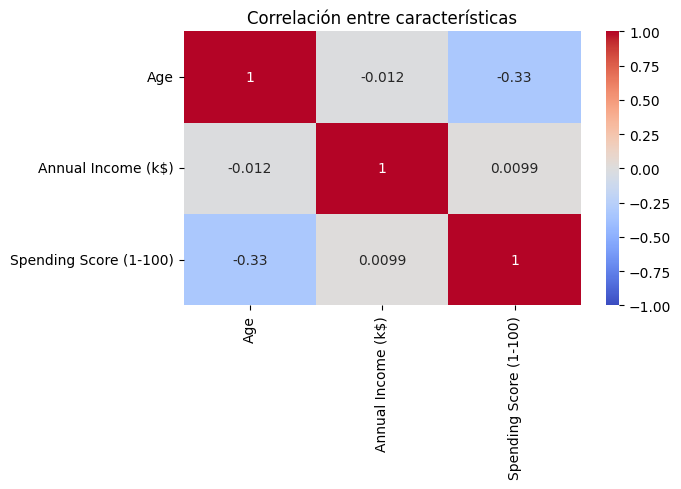

In [ ]:
variables = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[variables].copy()

print(X.head())

correlacion = X.corr()

plt.figure(figsize=(7,5))

sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlación entre características")
plt.tight_layout()
plt.show()

# **Actividad 4. Estandarización de datos**

In [ ]:
escalador = StandardScaler()

X_escalado = escalador.fit_transform(X)

df_escalado = pd.DataFrame(
    X_escalado,
    columns=variables
)

print(df_escalado.head())

print("Medias:")
print(df_escalado.mean())

print("Desviaciones estándar:")
print(df_escalado.std(ddof=0))

        Age  Annual Income (k$)  Spending Score (1-100)
0 -1.424569           -1.738999               -0.434801
1 -1.281035           -1.738999                1.195704
2 -1.352802           -1.700830               -1.715913
3 -1.137502           -1.700830                1.040418
4 -0.563369           -1.662660               -0.395980
Medias:
Age                      -1.021405e-16
Annual Income (k$)       -2.131628e-16
Spending Score (1-100)   -1.465494e-16
dtype: float64
Desviaciones estándar:
Age                       1.0
Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64


# **Actividad 5. Aplicación inicial de PCA**

In [ ]:
pca_completo = PCA(n_components=3)

X_pca_completo = pca_completo.fit_transform(X_escalado)

varianza = pca_completo.explained_variance_ratio_

varianza_acumulada = np.cumsum(varianza)

tabla_varianza = pd.DataFrame({
    "Componente":["PC1","PC2","PC3"],
    "Varianza explicada": varianza,
    "Varianza acumulada": varianza_acumulada
})

print(tabla_varianza.round(4))

  Componente  Varianza explicada  Varianza acumulada
0        PC1              0.4427              0.4427
1        PC2              0.3331              0.7757
2        PC3              0.2243              1.0000


# **Actividad 6. Visualización de la varianza explicada**

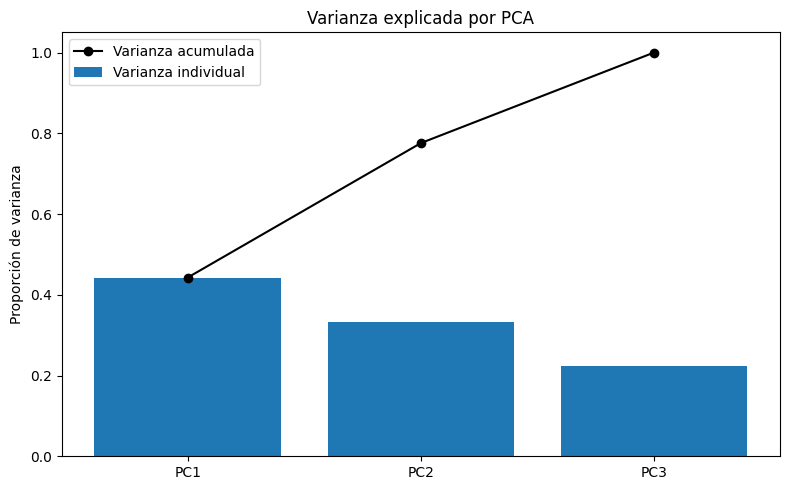

In [ ]:
componentes = ["PC1","PC2","PC3"]

plt.figure(figsize=(8,5))

plt.bar(
    componentes,
    varianza,
    label="Varianza individual"
)

plt.plot(
    componentes,
    varianza_acumulada,
    marker="o",
    color="black",
    label="Varianza acumulada"
)

plt.ylabel("Proporción de varianza")
plt.title("Varianza explicada por PCA")

plt.ylim(0,1.05)

plt.legend()

plt.tight_layout()
plt.show()

# **Actividad 7. Reducción de tres dimensiones a dos componentes**

In [ ]:
pca_2d = PCA(n_components=2)

X_pca = pca_2d.fit_transform(X_escalado)

df_pca = pd.DataFrame(
    X_pca,
    columns=["PC1","PC2"]
)

print(df_pca.head())

varianza_2d = pca_2d.explained_variance_ratio_.sum()

print("Varianza conservada:", varianza_2d)
print("Porcentaje conservado:", varianza_2d * 100)

        PC1       PC2
0 -0.615720 -1.763481
1 -1.665793 -1.820747
2  0.337862 -1.674799
3 -1.456573 -1.772430
4 -0.038465 -1.662740
Varianza conservada: 0.7757454566976747
Porcentaje conservado: 77.57454566976747


# **Actividad 8. Visualización PCA**

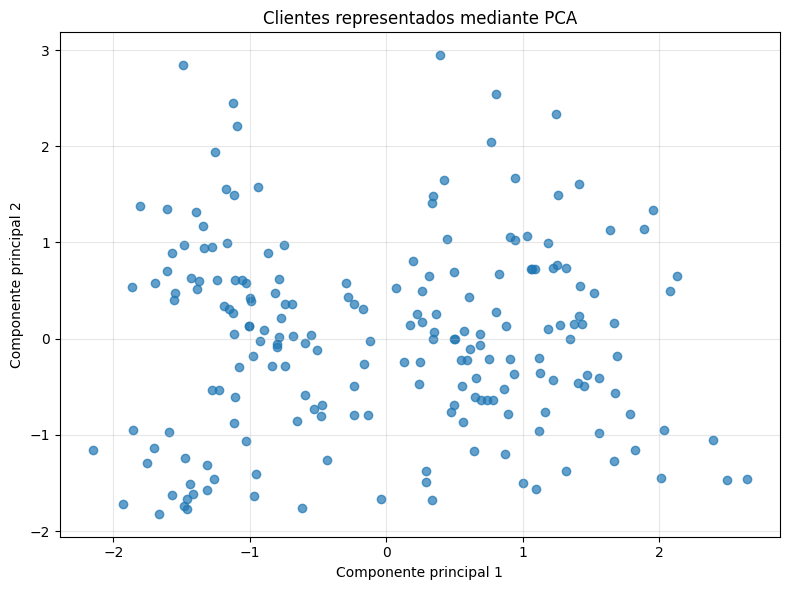

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df_pca["PC1"],
    df_pca["PC2"],
    alpha=0.7
)

plt.title("Clientes representados mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# **Actividad 9. Interpretación de componentes**

                           PC1     PC2
Age                     0.7064  0.0301
Annual Income (k$)     -0.0480  0.9988
Spending Score (1-100) -0.7062 -0.0378


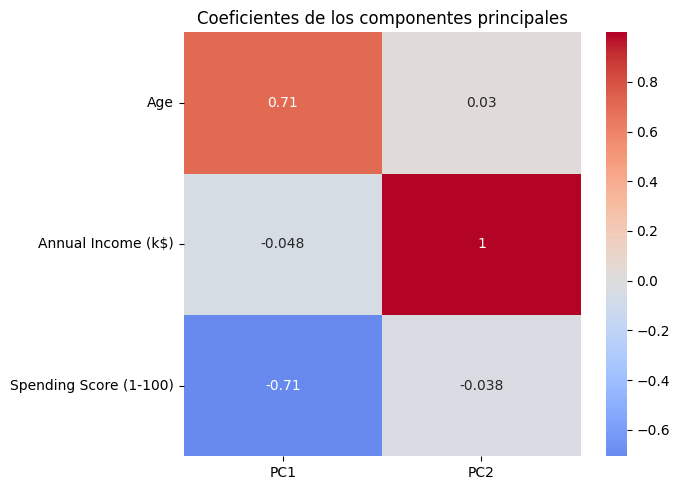

In [ ]:
coeficientes = pca_2d.components_

tabla_componentes = pd.DataFrame(
    coeficientes.T,
    index=variables,
    columns=["PC1","PC2"]
)

print(tabla_componentes.round(4))

plt.figure(figsize=(7,5))

sns.heatmap(
    tabla_componentes,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Coeficientes de los componentes principales")

plt.tight_layout()
plt.show()

# **Actividad 10. K-Means sobre datos originales**

In [ ]:
k = 5

kmeans_original = KMeans(
    n_clusters=k,
    n_init=10,
    random_state=42
)

etiquetas_original = kmeans_original.fit_predict(X_escalado)

silueta_original = silhouette_score(
    X_escalado,
    etiquetas_original
)

print("Silueta en espacio original:", silueta_original)

Silueta en espacio original: 0.41664341513732767


# **Actividad 11. Visualización de clústeres originales mediante PCA**

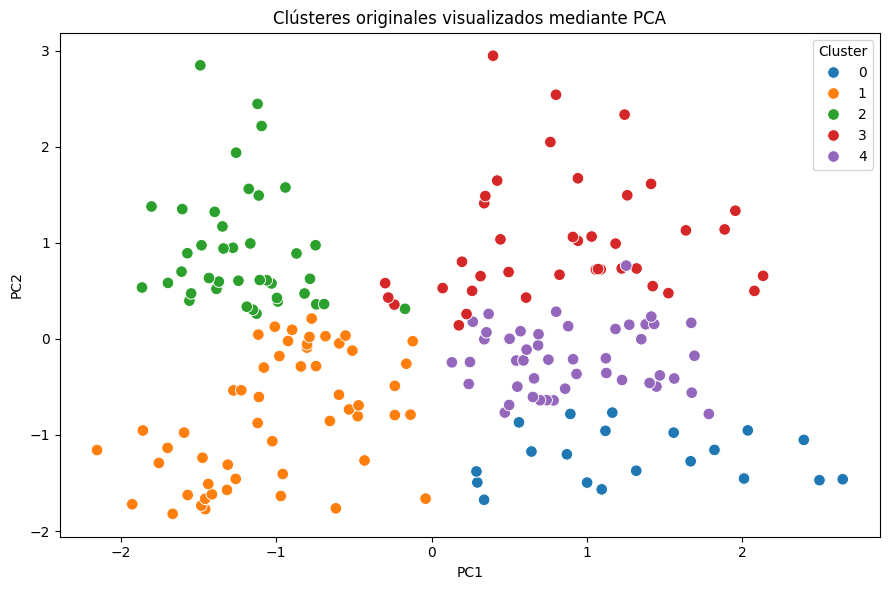

In [ ]:
df_visualizacion = df_pca.copy()

df_visualizacion["Cluster"] = etiquetas_original

plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df_visualizacion,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=70
)

plt.title("Clústeres originales visualizados mediante PCA")

plt.tight_layout()
plt.show()

# **Actividad 12. K-Means después de PCA**

Silueta en espacio PCA: 0.3930825006118691


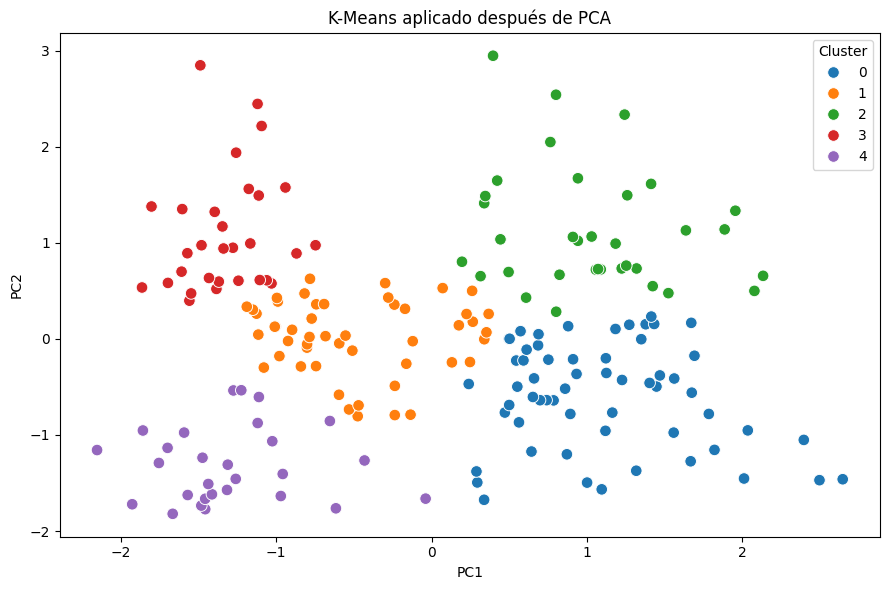

In [ ]:
kmeans_pca = KMeans(
    n_clusters=k,
    n_init=10,
    random_state=42
)

etiquetas_pca = kmeans_pca.fit_predict(X_pca)

silueta_pca = silhouette_score(
    X_pca,
    etiquetas_pca
)

print("Silueta en espacio PCA:", silueta_pca)

df_clusters_pca = df_pca.copy()

df_clusters_pca["Cluster"] = etiquetas_pca

plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df_clusters_pca,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=70
)

plt.title("K-Means aplicado después de PCA")

plt.tight_layout()
plt.show()

# **Actividad 13. Comparación de agrupamientos**

Índice de Rand ajustado: 0.5221358498802732
PCA        0   1   2   3   4
Original                    
0         20   0   0   0   0
1          0  26   0   0  28
2          0  10   0  30   0
3          0   7  32   0   0
4         39   6   2   0   0


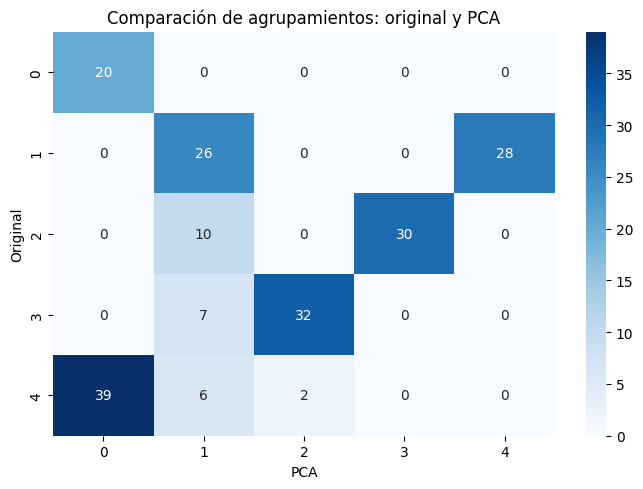

In [ ]:
ari = adjusted_rand_score(
    etiquetas_original,
    etiquetas_pca
)

print("Índice de Rand ajustado:", ari)

comparacion = pd.crosstab(
    pd.Series(etiquetas_original, name="Original"),
    pd.Series(etiquetas_pca, name="PCA")
)

print(comparacion)

plt.figure(figsize=(7,5))

sns.heatmap(
    comparacion,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Comparación de agrupamientos: original y PCA")

plt.tight_layout()
plt.show()

# **ACTIVIDAD EXTRA (RETO)**

PCA automático conservando 90% de la varianza

In [ ]:
umbral = 0.90

pca_reto = PCA(
    n_components=umbral
)

X_reto = pca_reto.fit_transform(
    X_escalado
)

n_componentes = pca_reto.n_components_

varianza_retenida = (
    pca_reto.explained_variance_ratio_.sum()
)

print("Componentes seleccionados:", n_componentes)
print("Varianza conservada:", varianza_retenida)

Componentes seleccionados: 3
Varianza conservada: 1.0


K-Means usando los componentes seleccionados

In [ ]:
modelo_reto = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=42
)

etiquetas_reto = modelo_reto.fit_predict(
    X_reto
)

silueta_reto = silhouette_score(
    X_reto,
    etiquetas_reto
)

ari_reto = adjusted_rand_score(
    etiquetas_original,
    etiquetas_reto
)

print("Silueta del modelo reducido:", silueta_reto)
print("ARI respecto al modelo original:", ari_reto)

Silueta del modelo reducido: 0.41664341513732756
ARI respecto al modelo original: 1.0
